#### Imports

In [1]:
import sys
import tifffile
import numpy as np
import matplotlib.pyplot as plt
from findmaxima2d import find_maxima, find_local_maxima

In [2]:
sys.path.append('/home/dafei/git/MS2')

In [3]:
from ms2.tracking import get_masks_paths

#### Function

In [4]:
def get_z_projection_mask(mask: np.ndarray) -> np.ndarray:
    """
    Binary z-projection (any cell present) of a 3D labeled mask (Z, Y, X) -> (Y, X).
    Returns uint8 array with 1 where any label > 0 appears.
    """
    if mask.ndim != 3:
        raise ValueError("Input mask must be a 3D array (Z, Y, X)")
    return ((mask > 0).any(axis=0)).astype(np.uint8)

def get_cell_footprints(mask: np.ndarray) -> dict:
    """
    For each cell label > 0 in a 3D mask (Z, Y, X), build a 2D footprint (union over Z).
    Returns: {label: 2D boolean array}
    """
    if mask.ndim != 3:
        raise ValueError("mask must be 3D (Z, Y, X)")
    footprints = {}
    for label in np.unique(mask):
        if label == 0:
            continue
        fp = (mask == label).any(axis=0)
        if fp.any():
            footprints[label] = fp
    return footprints

def draw_z_projected_cell_outlines(mask3d: np.ndarray,
                                   image2d: np.ndarray,
                                   peaks: np.ndarray,
                                   ax=None,
                                   cmap=plt.cm.tab20,
                                   linewidth=0.8,
                                   alpha=0.9,
                                   max_labels: int | None = None,
                                   title: str | None = None):
    """
    Draw per-cell outlines (z-projected) over a provided 2D image.

    mask3d : 3D labeled array (Z, Y, X)
    image2d: 2D array (Y, X) to draw on (e.g. intensity projection)
    ax      matplotlib Axes (created if None)
    cmap    colormap used to assign colors per label
    linewidth, alpha styling
    max_labels: optionally limit number of labels (first N) for speed/clarity

    Returns (ax, footprints)
    """
    if mask3d.ndim != 3:
        raise ValueError("mask3d must be 3D (Z, Y, X)")
    if image2d.shape != mask3d.shape[1:]:
        raise ValueError("image2d shape must match (Y, X) of mask3d")

    footprints = get_cell_footprints(mask3d)
    labels = sorted(footprints.keys())
    if max_labels is not None:
        labels = labels[:max_labels]

    if ax is None:
        fig, ax = plt.subplots(figsize=(6, 4), constrained_layout=True)

    ax.imshow(image2d, cmap='gray')

    n_colors = cmap.N
    for i, label in enumerate(labels):
        fp = footprints[label].astype(float)
        # Use contour to get an outline
        color = cmap((i % n_colors) / n_colors)
        ax.contour(fp, levels=[0.5], colors=[color], linewidths=linewidth, alpha=alpha)
    ax.scatter(peaks[:, 0], peaks[:, 1], c='red', s=1)

    ax.set_axis_off()
    ax.set_title(title)
    return fig, ax, footprints


#### Inputs

In [ ]:
seg_maps_dir ="/zjbd/zd1/shechtmanlab/omer/MS2/outputs/020626/STAGE-12/New-03-V/New-03-V/masks/"
ms2_filtered_z_projection = "/zjbd/zd1/shechtmanlab/omer/MS2/data/020626/STAGE-12/New-03-V/SUM_C1-New-03-V_bg_removal.tif"

In [6]:
timepoint_debug = 0

In [7]:
ms2_z_projections = tifffile.imread(ms2_filtered_z_projection)
masks_paths = get_masks_paths(seg_maps_dir)

KeyboardInterrupt: 

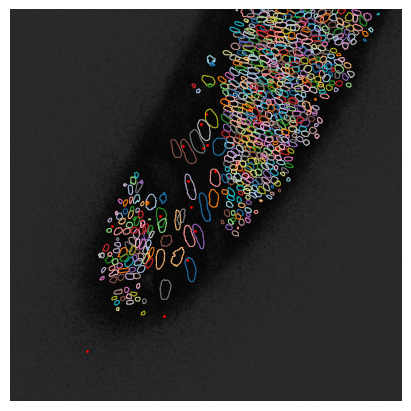

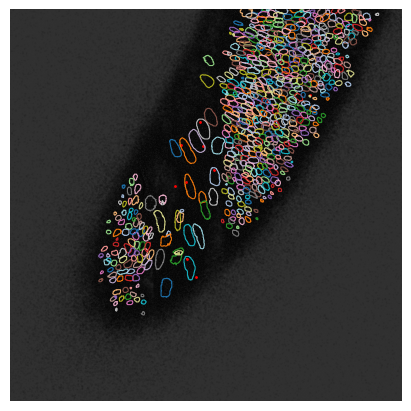

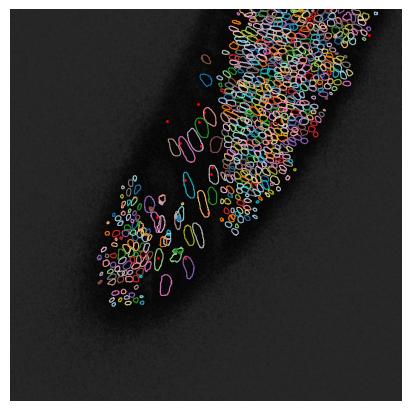

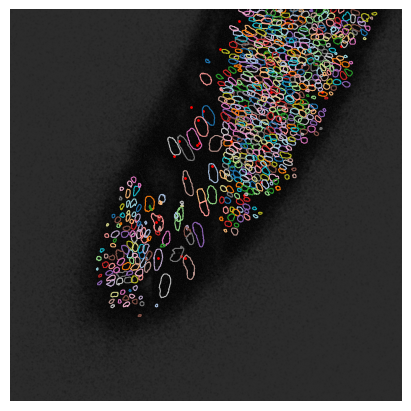

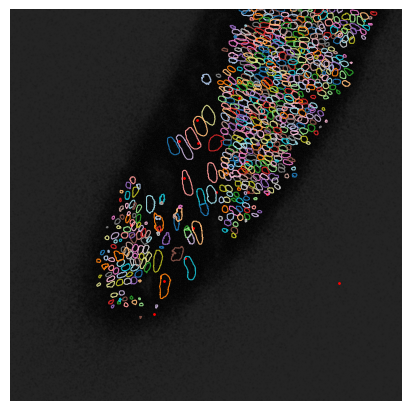

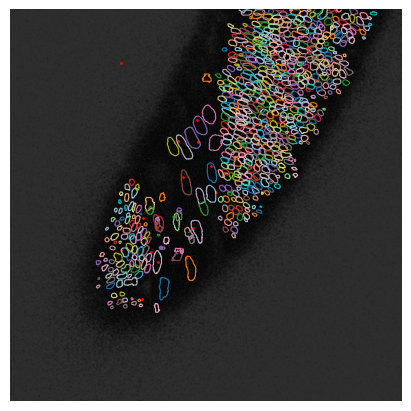

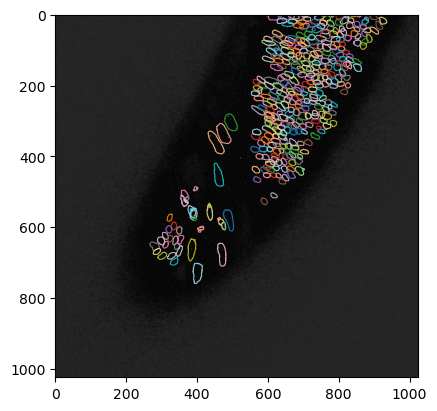

In [13]:
for timepoint in range(0,ms2_z_projections.shape[0]):
    masks_t = np.load(masks_paths[timepoint])['masks']
    ms2_projection_t = ms2_z_projections[timepoint]
    z_projection_cells = get_z_projection_mask(masks_t)
    local_max = find_local_maxima(ms2_projection_t)
    y, x, regs = find_maxima(ms2_projection_t, local_max, 20)
    peaks = np.array((x, y)).T
    fig, ax, footprints = draw_z_projected_cell_outlines(masks_t, ms2_projection_t, peaks=peaks)

In [9]:
masks_t = np.load(masks_paths[timepoint_debug])['masks']
ms2_projection_t = ms2_z_projections[timepoint_debug]

In [10]:
z_projection_cells = get_z_projection_mask(masks_t)

In [11]:
local_max = find_local_maxima(ms2_projection_t)
y, x, regs = find_maxima(ms2_projection_t, local_max, 20)
peaks = np.array((x, y)).T


ValueError: too many values to unpack (expected 2)

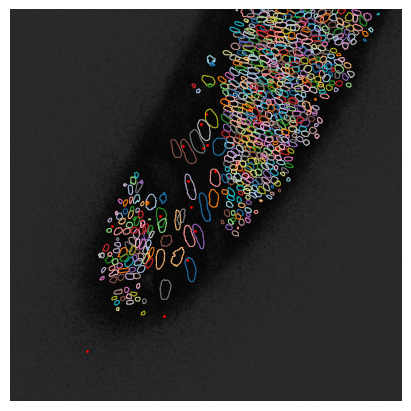

In [ ]:
fig, ax, footprints = draw_z_projected_cell_outlines(masks_t, ms2_projection_t, peaks=peaks)
plt.show()